<a href="https://colab.research.google.com/github/abhinavgautam08/Cyber-LAB-3/blob/main/Cyber_Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!rm -rf /content/sample_data/

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
df = pd.read_csv('simple_cyber_activity.csv')
features = ['failed_logins', 'login_hour','new_device', 'data_transfer_mb']
X = df[features]
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.25,random_state=42,stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Training shape:', X_train_scaled.shape)
print('Testing shape:', X_test_scaled.shape)

Training shape: (75, 4)
Testing shape: (25, 4)


In [3]:
import tensorflow as tf
np.random.seed(42)
tf.random.set_seed(42)
model = tf.keras.Sequential([ tf.keras.layers.Input(shape=(4,)),tf.keras.layers.Dense(8, activation='relu'),tf.keras.layers.Dense(4, activation='relu'),tf.keras.layers.Dense(1, activation='sigmoid')])
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
model.summary()
history = model.fit( X_train_scaled,y_train,validation_split=0.20,epochs=20,batch_size=8,verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.3167 - loss: 0.7647 - val_accuracy: 0.6000 - val_loss: 0.6900
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3833 - loss: 0.7529 - val_accuracy: 0.6667 - val_loss: 0.6826
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4000 - loss: 0.7424 - val_accuracy: 0.6667 - val_loss: 0.6755
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4500 - loss: 0.7325 - val_accuracy: 0.6667 - val_loss: 0.6687
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4500 - loss: 0.7235 - val_accuracy: 0.8000 - val_loss: 0.6624
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4667 - loss: 0.7154 - val_accuracy: 0.8667 - val_loss: 0.6564
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4833 - loss: 0.7079 - val_accuracy: 0.8667 - val_loss: 0.6512
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5333 - loss: 0.7008 - val_accuracy: 0.8667 - val_loss: 0.6462
Epoch 9

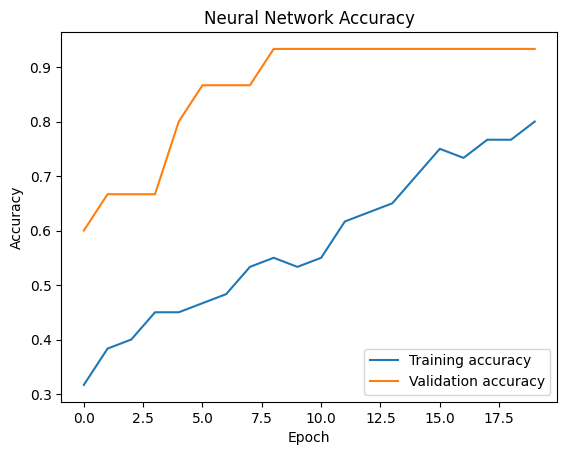

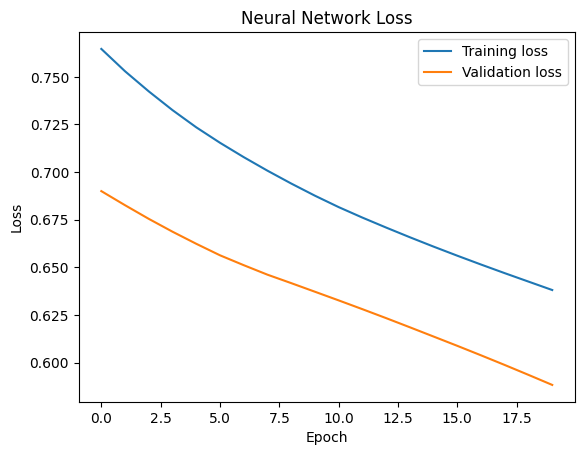

Test accuracy: 80.00%
Test loss: 0.6368


In [4]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()
test_loss, test_accuracy = model.evaluate(X_test_scaled,y_test,verbose=0)
print(f'Test accuracy: {test_accuracy * 100:.2f}%')
print(f'Test loss: {test_loss:.4f}')

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
new_records = pd.DataFrame([
{'failed_logins': 0, 'login_hour': 11,
'new_device': 0, 'data_transfer_mb': 35},
{'failed_logins': 7, 'login_hour': 1,
'new_device': 1, 'data_transfer_mb': 250},
{'failed_logins': 2, 'login_hour': 23,
'new_device': 1, 'data_transfer_mb': 850}
])
new_scaled = scaler.transform(new_records)
probabilities = model.predict(new_scaled, verbose=0).flatten()
new_records['nn_probability'] = probabilities.round(3)
new_records['nn_prediction'] = np.where(probabilities >= 0.50,'Attack','Normal')
tree = DecisionTreeClassifier(max_depth=4,random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)
new_records['tree_prediction'] = np.where(
tree.predict(new_records[features]) == 1,'Attack','Normal')
print(f'Neural-network accuracy: {test_accuracy * 100:.2f}%')
print(f'Decision-tree accuracy: {tree_accuracy * 100:.2f}%')
display(new_records)

Neural-network accuracy: 80.00%
Decision-tree accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.417,Normal,Normal
1,7,1,1,250,0.517,Attack,Attack
2,2,23,1,850,0.447,Normal,Attack
